# 02 - Golden batch and batch groups

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AHichem/resilient-process-monitoring/blob/main/notebooks/02_golden_batch_and_clusters.ipynb)

**Goal of this notebook**

1. Build a **golden batch**: the typical trajectory of a normal batch, with an envelope of normal variation (mean ± 3 standard deviations).
2. Use it as a first, **univariate** monitor (one variable at a time) and see where it works and where it fails.
3. Use **K-means** to check whether the batch groups can be found from the data alone, without labels.

**Prerequisite:** run notebook 01 once, so that the clean data is cached in Google Drive.

## 1. Loading

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/indpensim')
except ImportError:  # not running in Colab
    DATA_DIR = Path('data')

PROCESS_PARQUET = DATA_DIR / 'indpensim_process.parquet'
assert PROCESS_PARQUET.exists(), 'Run notebook 01 first to create the cached data.'

df = pd.read_parquet(PROCESS_PARQUET)
df['t'] = df['Time (h)'].astype('float64').round(1)  # clean time key, identical across batches
print(df.shape, '-', df['batch_id'].nunique(), 'batches')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(113935, 41) - 100 batches


Features naming simplification

In [5]:
INPUTS = {  # Inputs of the controlled system
    'Aeration rate(Fg:L/h)': 'aeration',
    'Agitator RPM(RPM:RPM)': 'agitator_rpm',
    'Sugar feed rate(Fs:L/h)': 'sugar_feed',
    'Acid flow rate(Fa:L/h)': 'acid_flow',
    'Base flow rate(Fb:L/h)': 'base_flow',
    'Heating/cooling water flow rate(Fc:L/h)': 'cooling_water',
    'Heating water flow rate(Fh:L/h)': 'heating_water',
    'Water for injection/dilution(Fw:L/h)': 'dilution_water',
    'Air head pressure(pressure:bar)': 'head_pressure',
    'Dumped broth flow(Fremoved:L/h)': 'dumped_broth',
    'PAA flow(Fpaa:PAA flow (L/h))': 'paa_flow',
    'Oil flow(Foil:L/hr)': 'oil_flow',
    'Ammonia shots(NH3_shots:kgs)': 'nh3_shots',
}
SENSORS = {  # measurements done online
    'Dissolved oxygen concentration(DO2:mg/L)': 'DO2',
    'pH(pH:pH)': 'pH',
    'Temperature(T:K)': 'temperature',
    'carbon dioxide percent in off-gas(CO2outgas:%)': 'CO2_offgas',
    'Oxygen in percent in off-gas(O2:O2  (%))': 'O2_offgas',
    'Vessel Weight(Wt:Kg)': 'weight',
}
COMPUTED = {  # derived from measurements
    'Vessel Volume(V:L)': 'volume',
    'Generated heat(Q:kJ)': 'heat',
    'Oxygen Uptake Rate(OUR:(g min^{-1}))': 'OUR',
    'Carbon evolution rate(CER:g/h)': 'CER',
}
OTHER = {
    'Penicillin concentration(P:g/L)': 'penicillin_true',     # target
    'Fault reference(Fault_ref:Fault ref)': 'fault',          # label
}
rename = {**INPUTS, **SENSORS, **COMPUTED, **OTHER}
missing_cols = [c for c in rename if c not in df.columns]
assert not missing_cols, f'Unexpected column names: {missing_cols}'
df = df.rename(columns=rename)

MONITOR_VARS = list(INPUTS.values()) + list(SENSORS.values()) + list(COMPUTED.values())
print(len(MONITOR_VARS), 'variables available to the monitor')

23 variables available to the monitor


## 2. Aligning batches of different lengths

**Absolute time normalization:** compare all batches at 50 h, 100 h, 150 h.

We use absolute time for the golden batch. The function below turns one variable into a matrix with **one row per batch and one column per time point**: the natural format for batch data.

In [10]:
def batch_matrix(data, var):
    """Rows = batches, columns = time (h). NaN after the end of a batch."""
    return data.pivot_table(index='batch_id', columns='t', values=var)

# example
do2 = batch_matrix(df, 'DO2')
print('Matrix shape (batches x time points):', do2.shape)
do2.head()

Matrix shape (batches x time points): (100, 1450)


t,0.2,0.4,0.6,0.8,1.0,1.2,1.4,1.6,1.8,2.0,...,288.2,288.4,288.6,288.8,289.0,289.2,289.4,289.6,289.8,290.0
batch_id,,,,,,,,,,,,,,,,,,,,,
1,14.711,14.699,14.686,14.661,14.633,14.621,14.604,14.583,14.547,14.529,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14.678,14.659,14.645,14.641,14.605,14.585,14.561,14.553,14.534,14.516,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,14.486,14.462,14.432,14.410,14.376,14.321,14.282,14.242,14.200,14.162,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,14.626,14.600,14.581,14.550,14.525,14.499,14.464,14.431,14.405,14.372,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,14.668,14.648,14.617,14.603,14.578,14.551,14.537,14.511,14.489,14.459,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. The golden batch

The golden batch is built from normal batches (from 1 to 90). For every time point we compute the mean and the standard deviation across batches. The band mean ± 3σ is the **envelope of normal variation**.

We only keep time points where at least 10 normal batches are still running, otherwise the statistics are not reliable.

In [15]:
batch_group = df.groupby('batch_id')['group'].first()
normal_ids = list(range(1, 91))    # batches 1-90
fault_ids  = list(range(91, 101))  # batches 91-100

def golden_batch(data, var, reference_ids, k=3, min_batches=10):
    m = batch_matrix(data, var).loc[reference_ids]
    stats = pd.DataFrame({'mean': m.mean(), 'std': m.std(), 'n_batches': m.count()})
    stats = stats[stats['n_batches'] >= min_batches] #min 10 to keep the stats relevant
    stats['low'] = stats['mean'] - k * stats['std']
    stats['high'] = stats['mean'] + k * stats['std']
    return stats

gb_do2 = golden_batch(df, 'DO2', normal_ids)
gb_do2.head()

,mean,std,n_batches,low,high
t,,,,,
0.2,14.690022,0.047543,90,14.547393,14.832652
0.4,14.671855,0.049657,90,14.522882,14.820827
0.6,14.654669,0.052996,90,14.495680,14.813658
0.8,14.635910,0.057532,90,14.463315,14.808505
1.0,14.613166,0.061592,90,14.428390,14.797942


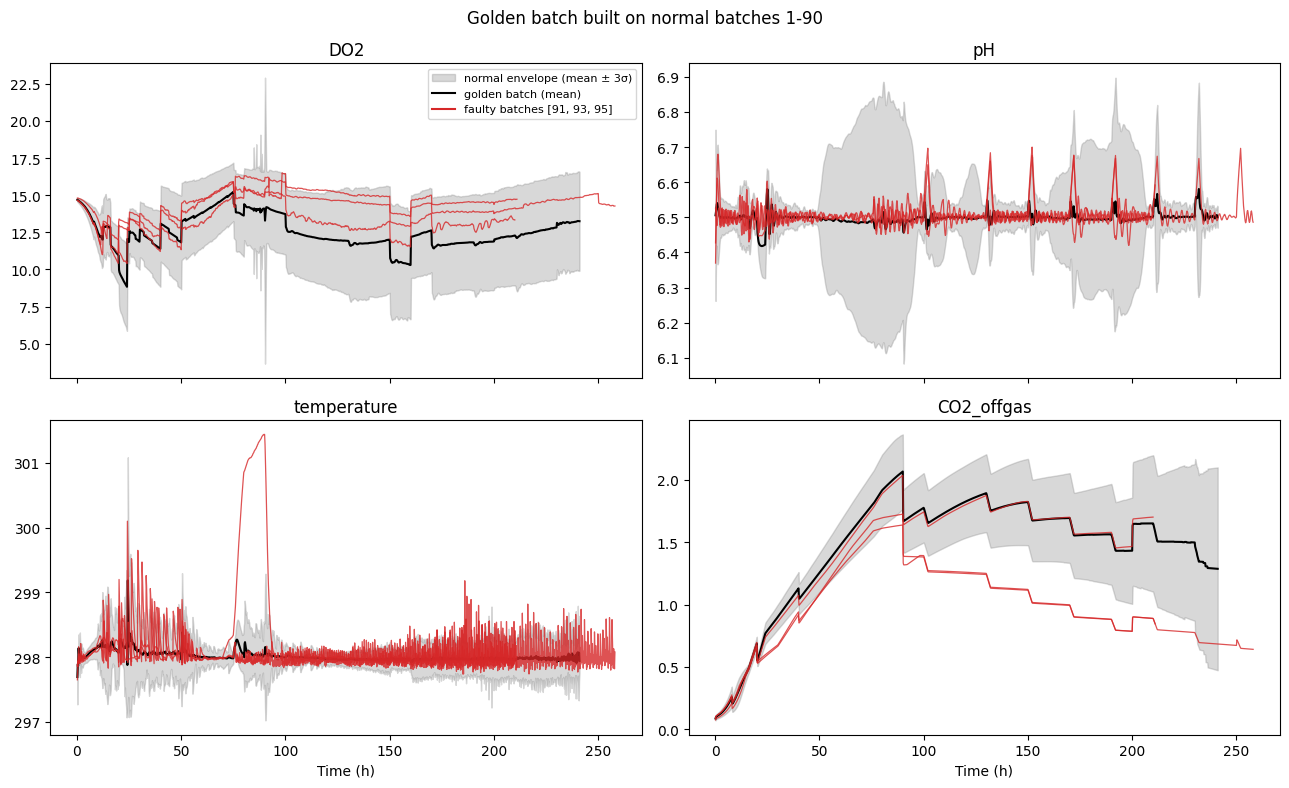

In [16]:
PLOT_VARS = ['DO2', 'pH', 'temperature', 'CO2_offgas']
show_faulty = [91, 93, 95]  # a few faulty batches to overlay

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, var in zip(axes.flat, PLOT_VARS):
    gb = golden_batch(df, var, normal_ids)
    ax.fill_between(gb.index, gb['low'], gb['high'], color='grey', alpha=0.3,
                    label='normal envelope (mean ± 3σ)')
    ax.plot(gb.index, gb['mean'], color='black', lw=1.5, label='golden batch (mean)')
    m = batch_matrix(df, var)
    for b in show_faulty:
        ax.plot(m.columns, m.loc[b], color='tab:red', lw=0.9, alpha=0.8)
    ax.plot([], [], color='tab:red', label=f'faulty batches {show_faulty}')
    ax.set_title(var)
for ax in axes[1]:
    ax.set_xlabel('Time (h)')
axes[0, 0].legend(fontsize=8)
plt.suptitle('Golden batch built on normal batches 1-90')
plt.tight_layout()
plt.show()

On DO2 the faulty batches stay inside the envelope, so DO2 alone is not a good fault indicator.

The envelope is wide. The faults are more visible on temperature and on CO2 in the off-gas.

### One golden batch per control strategy?

The three normal groups are run differently, so a single envelope is wide. Compare the DO2 envelope built on each group separately.

In [ ]:
colors = {'recipe': 'tab:blue', 'operator': 'tab:orange', 'APC (Raman)': 'tab:green'}
var = 'DO2'

fig, ax = plt.subplots(figsize=(11, 4))
for grp, c in colors.items():
    ids = batch_group[batch_group == grp].index
    gb = golden_batch(df, var, ids)
    ax.fill_between(gb.index, gb['low'], gb['high'], color=c, alpha=0.2)
    ax.plot(gb.index, gb['mean'], color=c, label=grp)
ax.set_xlabel('Time (h)'); ax.set_ylabel(var)
ax.set_title(f'{var}: golden batch and envelope per control strategy')
ax.legend()
plt.show()

## 4. A first monitor: one variable at a time

Simple rule: **raise an alarm at time t if at least one variable is outside its envelope.** We test it on all batches:

- on **normal batches**, every alarm is a **false alarm**;
- on **faulty batches**, we want an alarm soon after the fault starts.

Note: the envelope is built on the same normal batches we test, so the false alarm rate below is optimistic. Notebook 04 will use a proper train/test split.

In [ ]:
def out_of_envelope(data, var, reference_ids, k=3):
    """Boolean matrix (batches x time): True where the variable leaves the envelope."""
    gb = golden_batch(data, var, reference_ids, k=k)
    m = batch_matrix(data, var)[gb.index]
    outside = (m.lt(gb['low'], axis=1)) | (m.gt(gb['high'], axis=1))
    return outside & m.notna()

# Only keep variables that actually vary (a constant input has std = 0)
varying = [v for v in MONITOR_VARS if df.loc[df['batch_id'].isin(normal_ids), v].std() > 0]
print(len(varying), 'varying variables used')

alarms = None
for v in varying:
    o = out_of_envelope(df, v, normal_ids)
    alarms = o if alarms is None else (alarms | o.reindex_like(alarms).fillna(False))
running = batch_matrix(df, 'DO2').reindex(columns=alarms.columns).notna()

alarm_rate = (alarms & running).sum(axis=1) / running.sum(axis=1)
summary = pd.DataFrame({'group': batch_group, 'alarm_rate': alarm_rate})
summary.groupby('group')['alarm_rate'].describe()[['mean', 'min', 'max']].round(3)

In [ ]:
# Faulty batches: when does the first alarm come, compared with the fault start?
fault_m = batch_matrix(df, 'fault').reindex(columns=alarms.columns)

rows = []
for b in fault_ids:
    fault_times = fault_m.columns[fault_m.loc[b] == 1]
    start = fault_times.min() if len(fault_times) else np.nan
    alarm_times = alarms.columns[alarms.loc[b]]
    after = alarm_times[alarm_times >= start] if not np.isnan(start) else alarm_times[:0]
    rows.append({'batch_id': b, 'fault_start_h': start,
                 'first_alarm_h': alarm_times.min() if len(alarm_times) else np.nan,
                 'first_alarm_after_fault_h': after.min() if len(after) else np.nan})
detection = pd.DataFrame(rows).set_index('batch_id')
detection['delay_h'] = detection['first_alarm_after_fault_h'] - detection['fault_start_h']
detection

**Your turn - interpretation** *(write 2-3 sentences here)*

- What is the alarm rate on normal batches? With ~25 variables checked at ~1,100 time points each, even a rare 3σ excursion per variable adds up.
- Do some faulty batches raise an alarm **before** their fault starts? That would be a false alarm too.
- Which faults are detected quickly, which late or never?

**Why this motivates notebook 03:** a univariate monitor ignores the **correlations** between variables. A fault can keep every variable inside its own envelope while breaking the usual relationship between them, and many separate checks multiply false alarms. PCA watches all variables together.

## 5. K-means: can we find the batch groups without labels?

We describe each batch by a few numbers (mean and standard deviation of each monitor variable over the batch, plus its duration), then let K-means group similar batches. If the clusters match the control strategies, the strategies leave a clear signature in the data.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feat = df.groupby('batch_id')[varying].agg(['mean', 'std'])
feat.columns = [f'{v}_{s}' for v, s in feat.columns]
feat['duration_h'] = df.groupby('batch_id')['t'].max()
feat = feat.loc[:, feat.std() > 0]   # drop constant features

X = StandardScaler().fit_transform(feat)  # put all features on the same scale
print('Feature matrix:', X.shape, '(batches x features)')

**Choosing k.** K-means needs the number of clusters in advance. Two common guides: the *inertia* (within-cluster spread, look for an elbow) and the *silhouette score* (how well separated the clusters are, higher is better).

In [ ]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(list(ks), inertia, 'o-'); ax1.set_title('Inertia (look for an elbow)'); ax1.set_xlabel('k')
ax2.plot(list(ks), silhouette, 'o-'); ax2.set_title('Silhouette (higher is better)'); ax2.set_xlabel('k')
plt.tight_layout(); plt.show()

In [ ]:
K = 4  # try other values after looking at the two plots
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
feat['cluster'] = km.labels_

# Do the clusters match the control strategies?
pd.crosstab(feat['cluster'], batch_group.loc[feat.index], margins=True)

In [ ]:
# 2-D view of the batches (PCA projection - more on PCA in notebook 03)
from sklearn.decomposition import PCA

xy = PCA(n_components=2).fit_transform(X)
group_colors = {'recipe': 'tab:blue', 'operator': 'tab:orange',
                'APC (Raman)': 'tab:green', 'fault': 'tab:red'}
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(8, 6))
for i, b in enumerate(feat.index):
    ax.scatter(xy[i, 0], xy[i, 1], color=group_colors[batch_group[b]],
               marker=markers[feat.loc[b, 'cluster'] % len(markers)], s=50, alpha=0.8)
for g, c in group_colors.items():
    ax.scatter([], [], color=c, label=g)
ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2')
ax.set_title('Batches: colour = true group, marker = K-means cluster')
ax.legend()
plt.show()

**Your turn - interpretation** *(write 2-3 sentences here)*

- Does one cluster correspond to one control strategy? Which groups are mixed?
- Where do the faulty batches fall: in their own cluster, or among normal batches?
- Does a cluster gather the batches whose penicillin dropped after 150 h (notebook 01, section 5)?

## 6. Conclusions

*(Hichem - 3 to 5 bullet points: what the golden batch shows, how the univariate monitor performs, what K-means reveals, and what this means for notebook 03.)*